# 05 — SHAP Explainability

_Placeholder — SHAP TreeExplainer: global feature-importance summary and per-alert waterfall plots. SHAP overhead measured separately from inference latency._

In [1]:
import os, time
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt

d = joblib.load(os.path.join(os.getcwd(), "..", "data", "processed", "preprocessed.joblib"))
X_test, y_test = d["X_test"], d["y_test"]
feature_names, class_names = d["feature_names"], d["label_classes"]

stack = joblib.load(os.path.join(os.getcwd(), "..", "models", "stacking_model.joblib"))

# Extract the fitted XGBoost base learner from inside the stack and run it on CPU
xgb = stack.named_estimators_["xgb"].named_steps["xgb"]
xgb.set_params(device="cpu")     # SHAP on CPU; avoids GPU/CPU mismatch noise
explainer = shap.TreeExplainer(xgb)
print("Explainer ready on XGBoost base learner.")

C:\Users\OMEN\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Explainer ready on XGBoost base learner.


SHAP for 2000 samples in 1.12s  -> (2000, 64, 11)


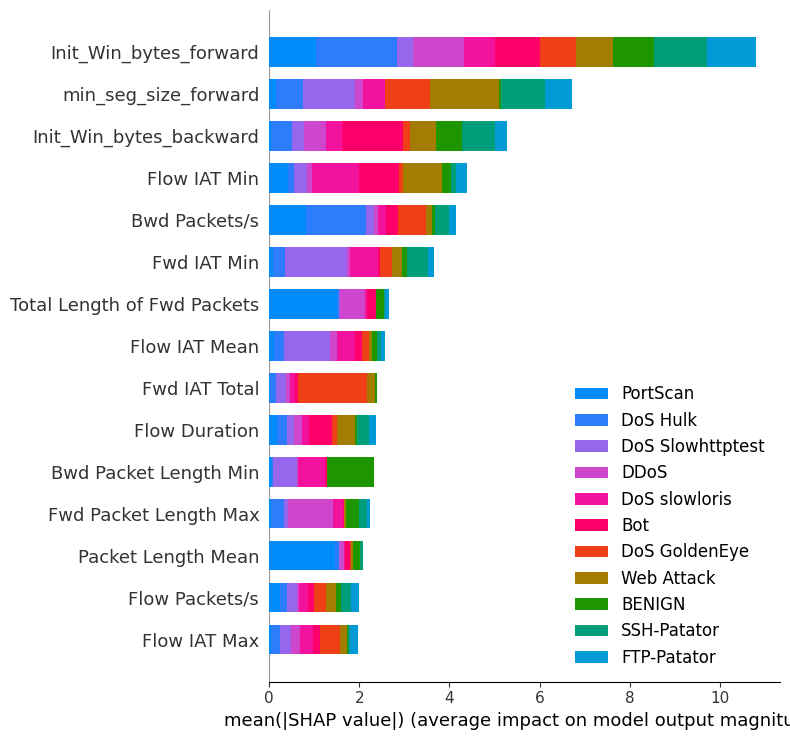

In [2]:
X_sample = X_test[:2000]                         # a representative slice
t0 = time.time()
sv = explainer.shap_values(X_sample)             # shape (2000, 64, n_classes)
print(f"SHAP for {len(X_sample)} samples in {time.time()-t0:.2f}s  -> {sv.shape}")

# multiclass bar: mean |SHAP| per feature, per class
shap.summary_plot(
    [sv[:, :, k] for k in range(sv.shape[2])], X_sample,
    feature_names=feature_names, class_names=class_names,
    plot_type="bar", max_display=15, show=True,
)

True: Bot   |   XGBoost base prediction: Bot


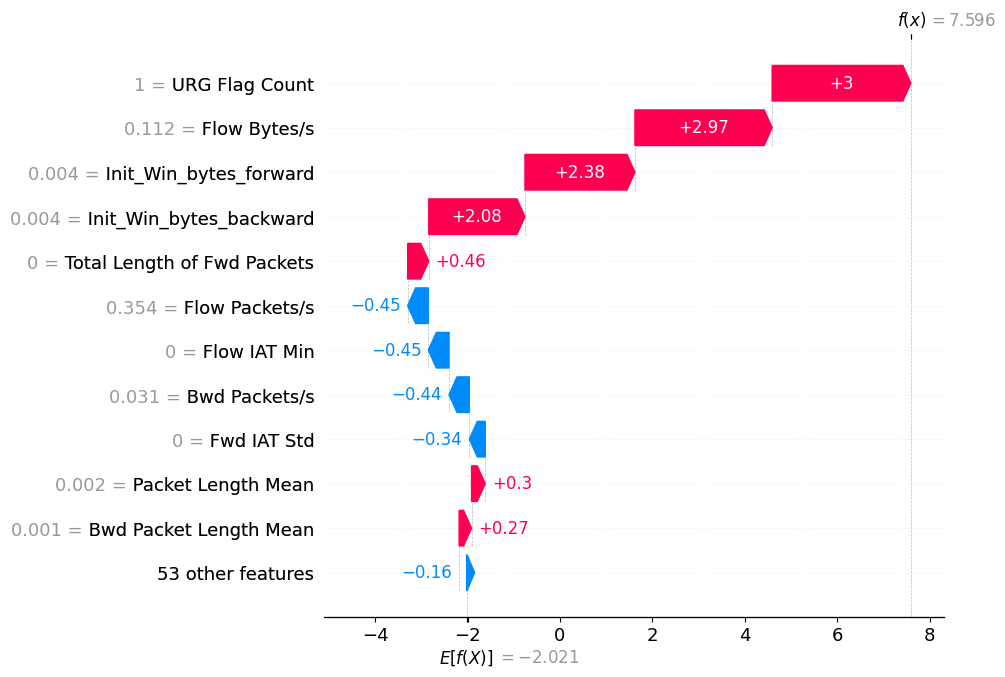


Top features driving this alert:
  URG Flag Count               increases 'Bot'  (SHAP +3.0032)
  Flow Bytes/s                 increases 'Bot'  (SHAP +2.9706)
  Init_Win_bytes_forward       increases 'Bot'  (SHAP +2.3802)
  Init_Win_bytes_backward      increases 'Bot'  (SHAP +2.0831)
  Total Length of Fwd Packets  increases 'Bot'  (SHAP +0.4568)
  Flow Packets/s               decreases 'Bot'  (SHAP -0.4478)
  Flow IAT Min                 decreases 'Bot'  (SHAP -0.4476)
  Bwd Packets/s                decreases 'Bot'  (SHAP -0.4404)


In [6]:
# Find a real Bot flow in the test set that the model flags as an attack
bot_idx = class_names.index("Bot")
candidates = np.where(y_test == bot_idx)[0]
i = int(candidates[0])                            # pick the first Bot flow

x_one = X_test[i:i+1]
pred = int(xgb.predict(x_one)[0])
print(f"True: {class_names[y_test[i]]}   |   XGBoost base prediction: {class_names[pred]}")

exp = explainer(x_one)  
exp.feature_names = feature_names     # so the waterfall shows real feature names                          # Explanation (1, 64, n_classes)
shap.plots.waterfall(exp[0, :, pred], max_display=12, show=True)

# The same info as text — this is exactly what the dashboard/API will return
vals = exp.values[0, :, pred]
order = np.argsort(np.abs(vals))[::-1][:8]
print("\nTop features driving this alert:")
for r in order:
    direction = "increases" if vals[r] > 0 else "decreases"
    print(f"  {feature_names[r]:28s} {direction} '{class_names[pred]}'  (SHAP {vals[r]:+.4f})")

In [4]:
# Inference latency: full stacking model, one flow
t0 = time.time()
for _ in range(100):
    stack.predict(X_test[i:i+1])
infer_ms = (time.time()-t0)/100*1000

# SHAP overhead: explaining one flow
t0 = time.time()
for _ in range(100):
    explainer(X_test[i:i+1])
shap_ms = (time.time()-t0)/100*1000

print(f"Inference latency : {infer_ms:.2f} ms / flow")
print(f"SHAP overhead     : {shap_ms:.2f} ms / flow")
print(f"Explanation adds  : {shap_ms/infer_ms:.1f}x on top of raw inference")

Inference latency : 36.83 ms / flow
SHAP overhead     : 9.41 ms / flow
Explanation adds  : 0.3x on top of raw inference
